## Function to Evaluate ML Models 

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(name, model, X_train, y_train, X_test, y_test, binary=True, class_names=None):
    print(f"\n=== {name} ===")

    start_train = time.time()
    model.fit(X_train, y_train)
    end_train = time.time()

    start_pred = time.time()
    y_pred = model.predict(X_test)
    end_pred = time.time()

    acc = accuracy_score(y_test, y_pred)
    train_time = end_train - start_train
    infer_time = end_pred - start_pred

    results = {
        'Model': name,
        'Accuracy': acc,
        'Training Time (s)': train_time,
        'Inference Time (s)': infer_time
    }

    if binary:
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec  = recall_score(y_test, y_pred, zero_division=0)
        f1   = f1_score(y_test, y_pred, zero_division=0)
        far  = fp / (fp + tn) if (fp + tn) > 0 else 0
        results.update({'Precision': prec, 'Recall': rec, 'F1 Score': f1, 'FAR': far})
        labels = ['Benign', 'Attack']
    else:
        prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
        rec  = recall_score(y_test, y_pred, average='weighted', zero_division=0)
        f1   = f1_score(y_test, y_pred, average='weighted', zero_division=0)
        results.update({
            'Precision (weighted)': prec,
            'Recall (weighted)': rec,
            'F1 Score (weighted)': f1
        })

        try:
            y_score = model.predict_proba(X_test)
            auc = roc_auc_score(y_test, y_score, multi_class='ovr', average='weighted')
            results['ROC-AUC (weighted)'] = auc
        except:
            results['ROC-AUC (weighted)'] = None

        # Per-class metrics
        print("\n Per-Class Metrics:")
        cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_names)))
        total = np.sum(cm)
        for i, label in enumerate(class_names):
            TP = cm[i, i]
            FP = cm[:, i].sum() - TP
            FN = cm[i, :].sum() - TP
            TN = total - (TP + FP + FN)
            far = FP / (FP + TN) if (FP + TN) > 0 else 0
            recall = recall_score(y_test, y_pred, labels=[i], average='macro', zero_division=0)
            f1_cls = f1_score(y_test, y_pred, labels=[i], average='macro', zero_division=0)
            print(f"  {label:<25} ➜ Recall: {recall:.3f} | F1: {f1_cls:.3f} | FAR: {far:.3f}")

        labels = list(class_names)

        # Print confusion matrix as text table
        cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
        print("\n Confusion Matrix Table:\n")
        print(cm_df.to_string())

    #  Plot confusion matrix heatmap
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        annot_kws={"size": 14}
    )
    plt.title(f"Confusion Matrix — {name}", fontsize=16)
    plt.ylabel("True label", fontsize=14)
    plt.xlabel("Predicted label", fontsize=14)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.tight_layout(pad=3)
    plt.show()

    return results


## Function to Evaluate DL Models 

In [ ]:


def evaluate_dl_model(name, model, X_test, y_test, class_names=None):
    print(f"\n=== {name} ===")

    start_pred = time.time()
    y_pred_raw = model.predict(X_test)
    end_pred = time.time()
    infer_time = end_pred - start_pred

    # Convert predictions
    if y_pred_raw.ndim > 1 and y_pred_raw.shape[1] > 1:
        y_pred = np.argmax(y_pred_raw, axis=1)
        y_true = np.argmax(y_test, axis=1)
        is_binary = False
    else:
        y_pred = (y_pred_raw > 0.5).astype(int).flatten()
        y_true = y_test
        is_binary = True

    acc = accuracy_score(y_true, y_pred)
    results = {
        'Model': name,
        'Accuracy': acc,
        'Training Time (s)': None,
        'Inference Time (s)': infer_time
    }

    if is_binary:
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        prec = precision_score(y_true, y_pred, zero_division=0)
        rec  = recall_score(y_true, y_pred, zero_division=0)
        f1   = f1_score(y_true, y_pred, zero_division=0)
        far  = fp / (fp + tn) if (fp + tn) > 0 else 0
        results.update({'Precision': prec, 'Recall': rec, 'F1 Score': f1, 'FAR': far})
        labels = ['Benign', 'Attack']
    else:
        prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
        rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
        f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
        results.update({
            'Precision (weighted)': prec,
            'Recall (weighted)': rec,
            'F1 Score (weighted)': f1
        })

        try:
            auc = roc_auc_score(y_true, y_pred_raw, multi_class='ovr', average='weighted')
            results['ROC-AUC (weighted)'] = auc
        except:
            results['ROC-AUC (weighted)'] = None

        # Per-class metrics
        print("\n Per-Class Metrics:")
        cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
        total = np.sum(cm)
        for i, label in enumerate(class_names):
            TP = cm[i, i]
            FP = cm[:, i].sum() - TP
            FN = cm[i, :].sum() - TP
            TN = total - (TP + FP + FN)
            far = FP / (FP + TN) if (FP + TN) > 0 else 0
            recall_i = recall_score(y_true, y_pred, labels=[i], average='macro', zero_division=0)
            f1_i = f1_score(y_true, y_pred, labels=[i], average='macro', zero_division=0)
            print(f"  {label:<25} ➜ Recall: {recall_i:.3f} | F1: {f1_i:.3f} | FAR: {far:.3f}")

        labels = list(class_names)

    # Summary
    print(f"\nAccuracy:               {acc:.4f}")
    print(f"⏱ Inference Time:       {infer_time:.2f} sec")
    if is_binary:
        print(f"Precision:              {prec:.4f}")
        print(f"Recall:                 {rec:.4f}")
        print(f"F1 Score:               {f1:.4f}")
        print(f"False Alarm Rate (FAR): {far:.4f}")
    else:
        print(f"Precision (weighted):   {prec:.4f}")
        print(f"Recall (weighted):      {rec:.4f}")
        print(f"F1 Score (weighted):    {f1:.4f}")
        if results['ROC-AUC (weighted)'] is not None:
            print(f" ROC-AUC (weighted):  {results['ROC-AUC (weighted)']:.4f}")
        else:
            print(" ROC-AUC could not be computed.")

    #  Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    cm_df = pd.DataFrame(cm,
                         index=[f"True {label}" for label in labels],
                         columns=[f"Pred {label}" for label in labels])
    print("\n Confusion Matrix Table (Text):")
    print(cm_df.to_string())

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels,
                annot_kws={"size": 14})
    plt.title(f"Confusion Matrix — {name}", fontsize=16)
    plt.ylabel("True label", fontsize=14)
    plt.xlabel("Predicted label", fontsize=14)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.tight_layout(pad=3)
    plt.show()

    return results


## Data Preprocessing and Feature Selection 

In [ ]:
# Load Data
file_path = r'C:\Users\user\CSE-CIC-IDS2018-Full\clean_sample.csv'
df = pd.read_csv(file_path)


### Multiclass Classification

In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

label_encoder = LabelEncoder()
df['Label_encoded'] = label_encoder.fit_transform(df['Label'])

X = df.drop(columns=['Label', 'Label_encoded'])
y = df['Label_encoded']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# XGBoost Feature Selection
xgb_model = XGBClassifier(n_estimators=100, max_depth=6, random_state=42, verbosity=0)
xgb_model.fit(X_train, y_train)

# Rank features
importances = xgb_model.feature_importances_
feature_names = X_train.columns
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Keep top 30 most important features 
top_n = 30
top_features = importance_df['Feature'].head(top_n).tolist()
print(f"Top {top_n} features selected:\n", top_features)

# Feature importance plot
plt.figure(figsize=(10, 8))
top_n_df = importance_df.sort_values(by='Importance', ascending=True).tail(top_n)
top_n_df.plot(kind='barh', x='Feature', y='Importance', legend=False)

plt.title("Top 30 Feature Importances (XGBoost - Multiclass)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.grid(True)
plt.savefig("xgb_feature_importance_multiclass.png", dpi=300)  # Optional
plt.show()

plt.show()

# Subset data to selected features 
X_train = X_train[top_features]
X_val   = X_val[top_features]
X_test  = X_test[top_features]

# Scale selected features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)


###  For Binary Classification 

In [ ]:

df['Label_binary'] = df['Label'].apply(lambda x: 0 if x == 'Benign' else 1)

X_bin = df.drop(columns=['Label', 'Label_encoded', 'Label_binary'])
y_bin = df['Label_binary']

Xb_train, Xb_temp, yb_train, yb_temp = train_test_split(
    X_bin, y_bin, test_size=0.30, stratify=y_bin, random_state=42)

Xb_val, Xb_test, yb_val, yb_test = train_test_split(
    Xb_temp, yb_temp, test_size=0.5, stratify=yb_temp, random_state=42)

# XGBoost Feature Selection 
xgb_bin = XGBClassifier(n_estimators=100, max_depth=6, random_state=42, verbosity=0)
xgb_bin.fit(Xb_train, yb_train)

importances_bin = xgb_bin.feature_importances_
feature_names_bin = Xb_train.columns
importance_df_bin = pd.DataFrame({'Feature': feature_names_bin, 'Importance': importances_bin})
importance_df_bin = importance_df_bin.sort_values(by='Importance', ascending=False)

# Select top 30 features
top_n_bin = 30
top_features_bin = importance_df_bin['Feature'].head(top_n_bin).tolist()
print(f"\n Top {top_n_bin} binary features:\n", top_features_bin)

# Plot feature importance 
plt.figure(figsize=(10, 8))
top30_bin_df = importance_df_bin.sort_values(by='Importance', ascending=True).tail(top_n)
top30_bin_df.plot(kind='barh', x='Feature', y='Importance', legend=False)

plt.title("Top 30 Feature Importances (XGBoost - Binary)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.grid(True)
plt.savefig("xgb_feature_importance_binary.png", dpi=300, bbox_inches='tight')  # optional for report
plt.show()


# Subset to most important features only 
Xb_train = Xb_train[top_features_bin]
Xb_val   = Xb_val[top_features_bin]
Xb_test  = Xb_test[top_features_bin]

# Scale
scaler_bin = StandardScaler()
Xb_train_scaled = scaler_bin.fit_transform(Xb_train)
Xb_val_scaled   = scaler_bin.transform(Xb_val)
Xb_test_scaled  = scaler_bin.transform(Xb_test)


## Train and Evaluate ML Models on the Reduced Data (Using only top features)


🔷 Multiclass — K-Nearest Neighbors

=== K-Nearest Neighbors (Multiclass) ===

🔍 Per-Class Metrics:
  Benign                    ➜ Recall: 0.999 | F1: 0.995 | FAR: 0.042
  Bot                       ➜ Recall: 0.999 | F1: 0.999 | FAR: 0.000
  Brute Force -Web          ➜ Recall: 0.222 | F1: 0.308 | FAR: 0.000
  Brute Force -XSS          ➜ Recall: 0.667 | F1: 0.571 | FAR: 0.000
  DDOS attack-HOIC          ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DDOS attack-LOIC-UDP      ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DDoS attacks-LOIC-HTTP    ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DoS attacks-GoldenEye     ➜ Recall: 1.000 | F1: 0.998 | FAR: 0.000
  DoS attacks-Hulk          ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DoS attacks-SlowHTTPTest  ➜ Recall: 0.722 | F1: 0.645 | FAR: 0.004
  DoS attacks-Slowloris     ➜ Recall: 0.964 | F1: 0.972 | FAR: 0.000
  FTP-BruteForce            ➜ Recall: 0.627 | F1: 0.686 | FAR: 0.002
  Infilteration             ➜ Recall: 0.285 | F1: 0.414 | FAR: 0.001
  S

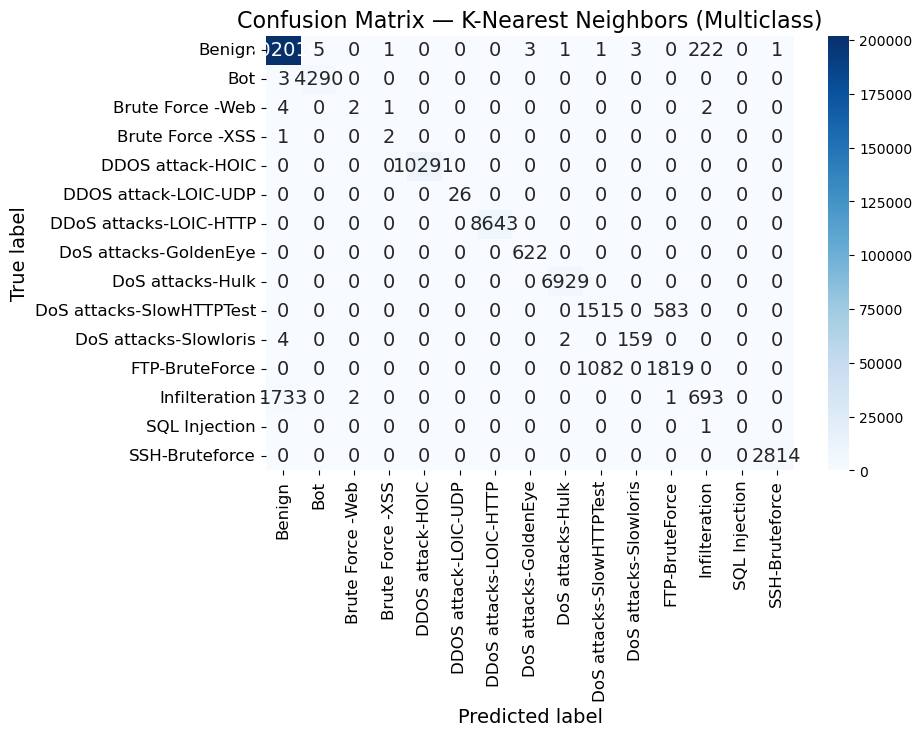


🔶 Binary — K-Nearest Neighbors

=== K-Nearest Neighbors (Binary) ===


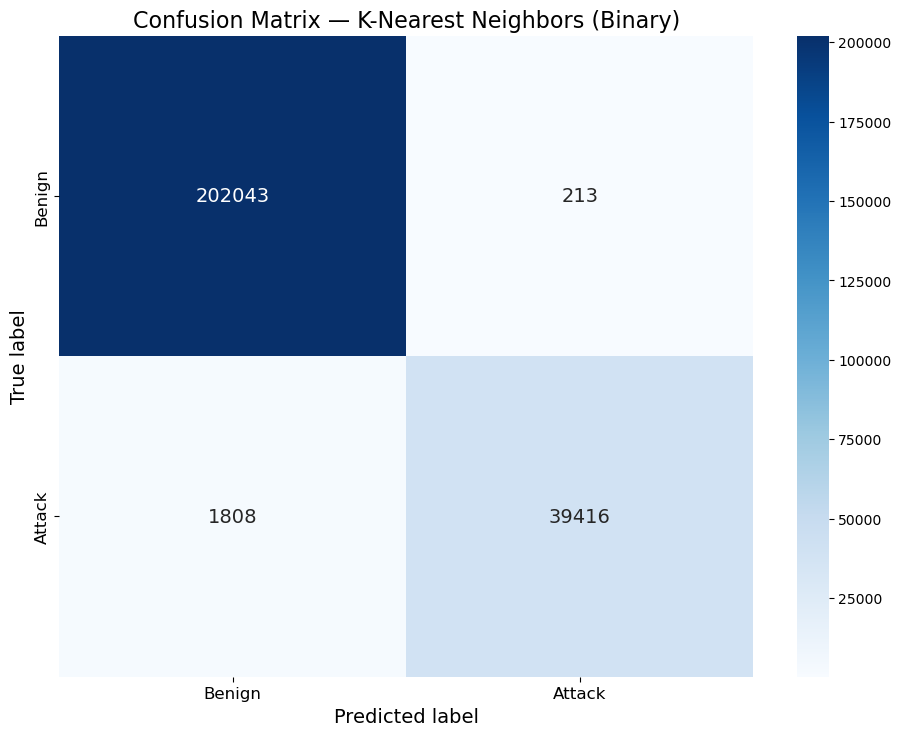


🔷 Multiclass — Decision Tree

=== Decision Tree (Multiclass) ===

🔍 Per-Class Metrics:
  Benign                    ➜ Recall: 1.000 | F1: 0.995 | FAR: 0.047
  Bot                       ➜ Recall: 0.998 | F1: 0.999 | FAR: 0.000
  Brute Force -Web          ➜ Recall: 0.222 | F1: 0.364 | FAR: 0.000
  Brute Force -XSS          ➜ Recall: 0.667 | F1: 0.800 | FAR: 0.000
  DDOS attack-HOIC          ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DDOS attack-LOIC-UDP      ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DDoS attacks-LOIC-HTTP    ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DoS attacks-GoldenEye     ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DoS attacks-Hulk          ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DoS attacks-SlowHTTPTest  ➜ Recall: 0.586 | F1: 0.602 | FAR: 0.003
  DoS attacks-Slowloris     ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  FTP-BruteForce            ➜ Recall: 0.738 | F1: 0.725 | FAR: 0.004
  Infilteration             ➜ Recall: 0.206 | F1: 0.337 | FAR: 0.000
  SQL Injection

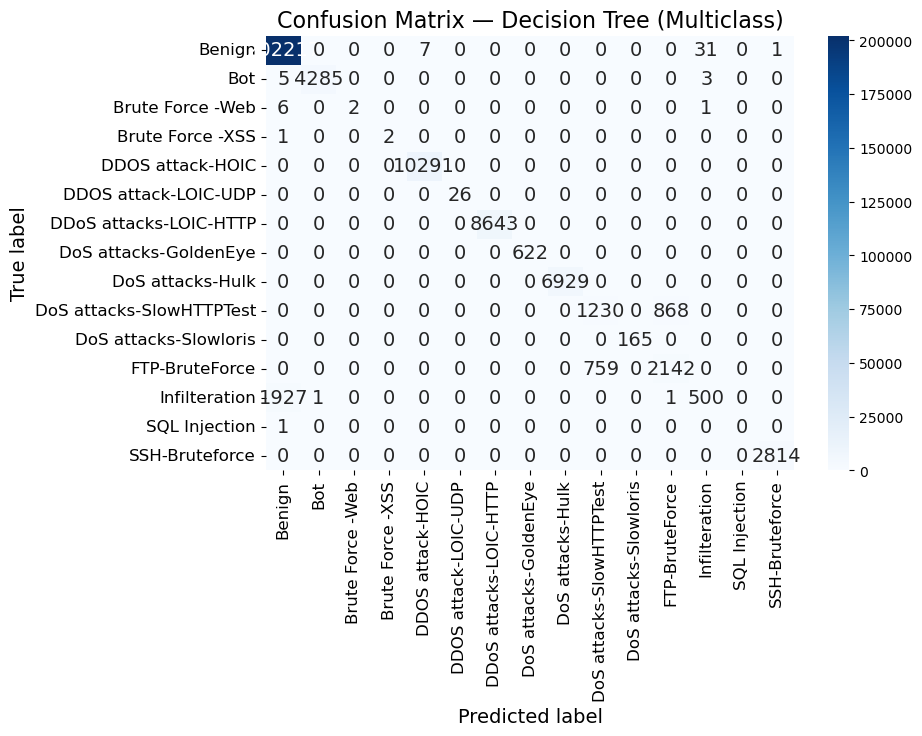


🔶 Binary — Decision Tree

=== Decision Tree (Binary) ===


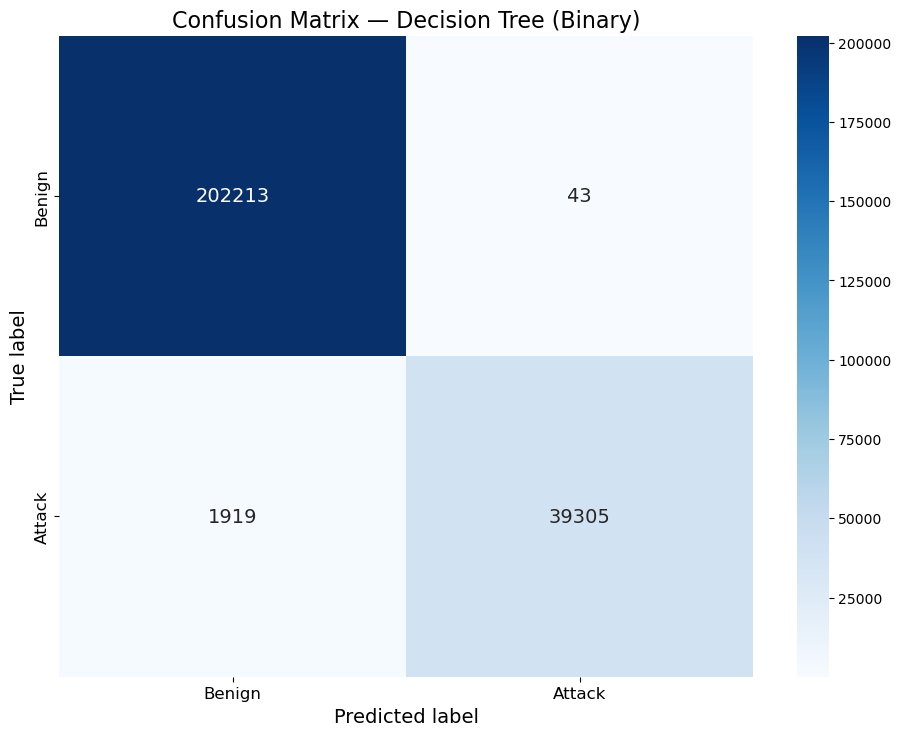


🔷 Multiclass — Random Forest

=== Random Forest (Multiclass) ===

🔍 Per-Class Metrics:
  Benign                    ➜ Recall: 0.991 | F1: 0.991 | FAR: 0.042
  Bot                       ➜ Recall: 0.999 | F1: 1.000 | FAR: 0.000
  Brute Force -Web          ➜ Recall: 0.222 | F1: 0.364 | FAR: 0.000
  Brute Force -XSS          ➜ Recall: 0.667 | F1: 0.800 | FAR: 0.000
  DDOS attack-HOIC          ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DDOS attack-LOIC-UDP      ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DDoS attacks-LOIC-HTTP    ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DoS attacks-GoldenEye     ➜ Recall: 1.000 | F1: 0.999 | FAR: 0.000
  DoS attacks-Hulk          ➜ Recall: 1.000 | F1: 1.000 | FAR: 0.000
  DoS attacks-SlowHTTPTest  ➜ Recall: 0.684 | F1: 0.647 | FAR: 0.004
  DoS attacks-Slowloris     ➜ Recall: 0.994 | F1: 0.997 | FAR: 0.000
  FTP-BruteForce            ➜ Recall: 0.688 | F1: 0.718 | FAR: 0.003
  Infilteration             ➜ Recall: 0.295 | F1: 0.295 | FAR: 0.007
  SQL Injection

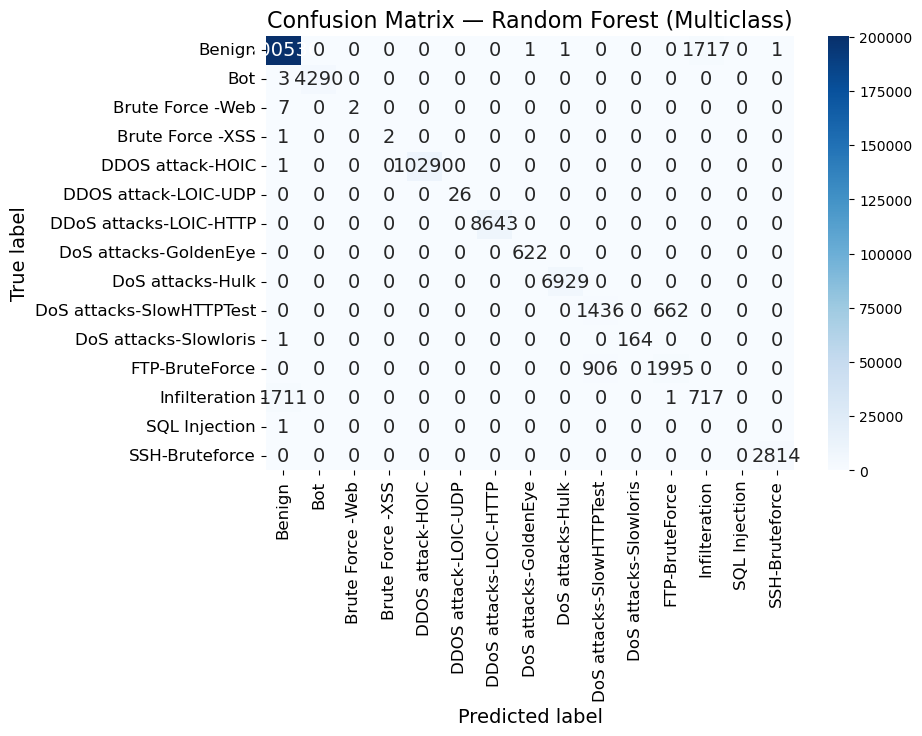


🔶 Binary — Random Forest

=== Random Forest (Binary) ===


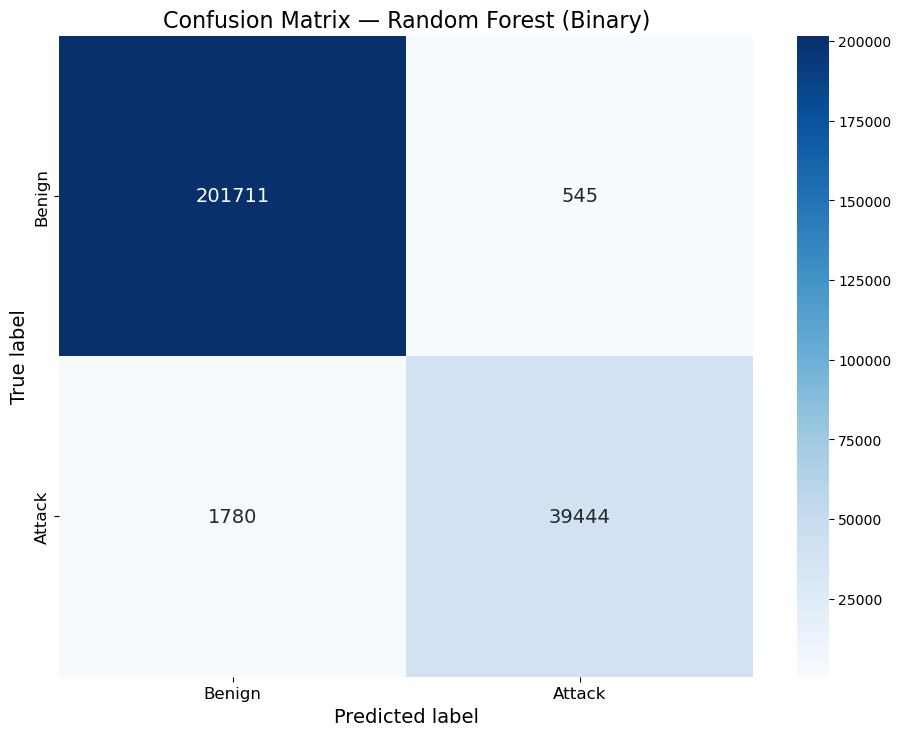

,Model,Accuracy,Training Time (s),Inference Time (s),Precision (weighted),Recall (weighted),F1 Score (weighted),ROC-AUC (weighted),Precision,Recall,F1 Score,FAR
0,K-Nearest Neighbors (Multiclass),0.984984,0.180190,286.651423,0.983863,0.984984,0.983216,0.984861,NaN,NaN,NaN,NaN
1,K-Nearest Neighbors (Binary),0.991700,0.219279,297.634879,NaN,NaN,NaN,NaN,0.994625,0.956142,0.975004,0.001053
2,Decision Tree (Multiclass),0.985165,12.649495,0.041668,0.984686,0.985165,0.982568,0.993111,NaN,NaN,NaN,NaN
3,Decision Tree (Binary),0.991942,13.183910,0.033038,NaN,NaN,NaN,NaN,0.998907,0.953449,0.975649,0.000213
4,Random Forest (Multiclass),0.979407,276.715461,3.506707,0.979556,0.979407,0.979439,0.990541,NaN,NaN,NaN,NaN
5,Random Forest (Binary),0.990451,246.091770,2.424063,NaN,NaN,NaN,NaN,0.986371,0.956821,0.971372,0.002695


In [ ]:


from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
}

all_results = []

for name, model in models.items():
    print(f"\n Multiclass — {name}")
    result_multi = evaluate_model(
        name=f"{name} (Multiclass)",
        model=model,
        X_train=X_train_scaled,
        y_train=y_train,
        X_test=X_test_scaled,
        y_test=y_test,
        binary=False,
        class_names=label_encoder.classes_
    )
    all_results.append(result_multi)

    print(f"\n Binary — {name}")
    result_bin = evaluate_model(
        name=f"{name} (Binary)",
        model=model,
        X_train=Xb_train_scaled,
        y_train=yb_train,
        X_test=Xb_test_scaled,
        y_test=yb_test,
        binary=True
    )
    all_results.append(result_bin)

results_df = pd.DataFrame(all_results)
display(results_df)


## CNN - Multiclass Classification Using Reduced Data 

In [ ]:

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import random
import numpy as np
import tensorflow as tf

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)


y_train_cat = to_categorical(y_train)
y_val_cat = to_categorical(y_val)
y_test_cat = to_categorical(y_test)

X_train_cnn = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_val_cnn   = X_val_scaled.reshape(X_val_scaled.shape[0], X_val_scaled.shape[1], 1)
X_test_cnn  = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

model = Sequential([
    Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(X_train_cnn.shape[1], 1)),
    MaxPooling1D(pool_size=2),
    Dropout(0.3),

    Conv1D(filters=128, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Dropout(0.3),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(y_train_cat.shape[1], activation='softmax')  # number of classes
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    X_train_cnn, y_train_cat,
    validation_data=(X_val_cnn, y_val_cat),
    epochs=30,
    batch_size=128,
    callbacks=[es],
    verbose=1
)

# Accuracy Plot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

evaluate_dl_model(
    name="CNN Multiclass",
    model=model,
    X_test=X_test_cnn,
    y_test=y_test_cat,
    class_names=label_encoder.classes_ 
)


## CNN - Binary Classification Using Reduced Data 

In [ ]:

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

Xb_train_cnn = Xb_train_scaled.reshape(Xb_train_scaled.shape[0], Xb_train_scaled.shape[1], 1)
Xb_val_cnn   = Xb_val_scaled.reshape(Xb_val_scaled.shape[0], Xb_val_scaled.shape[1], 1)
Xb_test_cnn  = Xb_test_scaled.reshape(Xb_test_scaled.shape[0], Xb_test_scaled.shape[1], 1)

model_bin_cnn = Sequential([
    Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(Xb_train_cnn.shape[1], 1)),
    MaxPooling1D(pool_size=2),
    Dropout(0.3),

    Conv1D(filters=128, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Dropout(0.3),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')  
])

model_bin_cnn.compile(optimizer='adam',
                      loss='binary_crossentropy',
                      metrics=['accuracy'])
es_bin = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history_bin_cnn = model_bin_cnn.fit(
    Xb_train_cnn, yb_train,
    validation_data=(Xb_val_cnn, yb_val),
    epochs=30,
    batch_size=128,
    callbacks=[es_bin],
    verbose=1
)

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_bin_cnn.history['accuracy'], label='Train Acc')
plt.plot(history_bin_cnn.history['val_accuracy'], label='Val Acc')
plt.title('CNN Binary Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_bin_cnn.history['loss'], label='Train Loss')
plt.plot(history_bin_cnn.history['val_loss'], label='Val Loss')
plt.title('CNN Binary Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

results_bin_cnn = evaluate_dl_model(
    name="CNN Binary",
    model=model_bin_cnn,
    X_test=Xb_test_cnn,
    y_test=yb_test,
    class_names=['Benign', 'Attack']
)

pd.DataFrame([results_bin_cnn])


## LSTM - Multiclass Using Reduced Data 

In [ ]:
import numpy as np
import tensorflow as tf
import random

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

y_train_cat = to_categorical(y_train)
y_val_cat   = to_categorical(y_val)
y_test_cat  = to_categorical(y_test)

X_train_lstm = X_train_scaled.reshape(X_train_scaled.shape[0], 1, X_train_scaled.shape[1])
X_val_lstm   = X_val_scaled.reshape(X_val_scaled.shape[0], 1, X_val_scaled.shape[1])
X_test_lstm  = X_test_scaled.reshape(X_test_scaled.shape[0], 1, X_test_scaled.shape[1])

model_lstm = Sequential([
    LSTM(128, input_shape=(1, X_train_scaled.shape[1]), return_sequences=False),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(y_train_cat.shape[1], activation='softmax')
])

model_lstm.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

es_lstm = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history_lstm = model_lstm.fit(
    X_train_lstm, y_train_cat,
    validation_data=(X_val_lstm, y_val_cat),
    epochs=30,
    batch_size=128,
    callbacks=[es_lstm],
    verbose=1
)

evaluate_dl_model(
    name="LSTM Multiclass",
    model=model_lstm,
    X_test=X_test_lstm,
    y_test=y_test_cat,
    class_names=label_encoder.classes_  
)

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_lstm.history['accuracy'], label='Train Accuracy')
plt.plot(history_lstm.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_lstm.history['loss'], label='Train Loss')
plt.plot(history_lstm.history['val_loss'], label='Val Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


## LSTM - Binary Using Reduced Data 

In [ ]:

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

Xb_train_lstm = Xb_train_scaled.reshape(Xb_train_scaled.shape[0], 1, Xb_train_scaled.shape[1])
Xb_val_lstm   = Xb_val_scaled.reshape(Xb_val_scaled.shape[0], 1, Xb_val_scaled.shape[1])
Xb_test_lstm  = Xb_test_scaled.reshape(Xb_test_scaled.shape[0], 1, Xb_test_scaled.shape[1])

model_bin_lstm = Sequential([
    LSTM(64, input_shape=(1, Xb_train_scaled.shape[1]), return_sequences=False),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model_bin_lstm.compile(optimizer='adam',
                       loss='binary_crossentropy',
                       metrics=['accuracy'])

es_bin_lstm = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history_bin_lstm = model_bin_lstm.fit(
    Xb_train_lstm, yb_train,
    validation_data=(Xb_val_lstm, yb_val),
    epochs=15,             
    batch_size=64,        
    callbacks=[es_bin_lstm],
    verbose=1
)

results_bin_lstm = evaluate_dl_model(
    name="LSTM Binary",
    model=model_bin_lstm,
    X_test=Xb_test_lstm,
    y_test=yb_test,
    class_names=['Benign', 'Attack']
)

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_bin_lstm.history['accuracy'], label='Train Accuracy')
plt.plot(history_bin_lstm.history['val_accuracy'], label='Val Accuracy')
plt.title('Binary LSTM Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_bin_lstm.history['loss'], label='Train Loss')
plt.plot(history_bin_lstm.history['val_loss'], label='Val Loss')
plt.title('Binary LSTM Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

